# Домашнее задание 2: Линейные модели. Работа с признаками

Задание выполнил(а):

    Володина Надежда

## Импорт библиотек и загрузка данных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

В этом задании мы рассмотрим различные аспекты построения линейной модели. Будем работать с одним из классических наборов данных в статистике, содержащим информацию о бриллиантах. Описание можно посмотреть [здесь](https://www.kaggle.com/shivam2503/diamonds).

In [3]:
DIAMONDS = 'https://raw.githubusercontent.com/evgpat/datasets/main/diamonds.csv'

In [4]:
data = pd.read_csv(DIAMONDS)
data.head(5)

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [5]:
# запишем в файл csv, чтобы лежал локально на компьютере
import urllib.request

urllib.request.urlretrieve(DIAMONDS, "diamonds.csv")

('diamonds.csv', <http.client.HTTPMessage at 0x1f039799910>)

Посмотрим на типы столбцов

In [5]:
data.dtypes

Unnamed: 0      int64
carat         float64
cut            object
color          object
clarity        object
depth         float64
table         float64
price           int64
x             float64
y             float64
z             float64
dtype: object

Мы будем решать задачу предсказания цены бриллианта `price` в зависимости от его характеристик.

## Построение модели

### Задание 1 (1 балл)

Есть ли в наборе данных пропущенные значения? Если да, удалите строки с ними.

Также выведите на экран число пропусков в каждом столбце.

In [6]:
# ваш код здесь
data.isnull().sum()

Unnamed: 0    0
carat         0
cut           0
color         0
clarity       0
depth         0
table         0
price         0
x             0
y             0
z             0
dtype: int64

Вывод: пропусков нет

### Задача 2 (1 балл)

Есть ли в наборе данных бессмысленные столбцы (признаки, не несущие дополнительной информации)?  
Если да, то удалите их. Поясните свой выбор (напишите текстом обоснование)

In [7]:
# ваш код здесь
data.drop(columns=['Unnamed: 0'], inplace=True)

In [8]:
data.columns

Index(['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y',
       'z'],
      dtype='object')

Да, в таблице был бессмысленный столбец 'Unnamed: 0', который обозначал просто номер по порядку. Я его удалила и проверила, правильно ли все удалилось.

### Задание 3 (1 балл)

Линейная регрессия основана на предположении о линейной связи между признаками и целевой переменной, а потому перед выбором переменных для включения в модель имеет смысл проверить, насколько эта связь выполняется. Для следующих пунктов нам также потребуются корреляции между признаками.  
Выведите матрицу корреляций между всеми вещественными признаками и целевой переменной.

Какой вещественный признак коррелирует с целевой переменной больше всего?

In [9]:
# ваш код здесь
data.corr(numeric_only=True)

,carat,depth,table,price,x,y,z
carat,1.000000,0.028224,0.181618,0.921591,0.975094,0.951722,0.953387
depth,0.028224,1.000000,-0.295779,-0.010647,-0.025289,-0.029341,0.094924
table,0.181618,-0.295779,1.000000,0.127134,0.195344,0.183760,0.150929
price,0.921591,-0.010647,0.127134,1.000000,0.884435,0.865421,0.861249
x,0.975094,-0.025289,0.195344,0.884435,1.000000,0.974701,0.970772
y,0.951722,-0.029341,0.183760,0.865421,0.974701,1.000000,0.952006
z,0.953387,0.094924,0.150929,0.861249,0.970772,0.952006,1.000000


Из вещественных признаков с целевой переменной больше всего коррелирует **'carat'**

In [10]:
np.linalg.matrix_rank(data.corr(numeric_only=True))

np.int64(7)

Выше проверила на всякий случай ранг матрицы корреляций. Пишет якобы мультиколлинеарности нет.

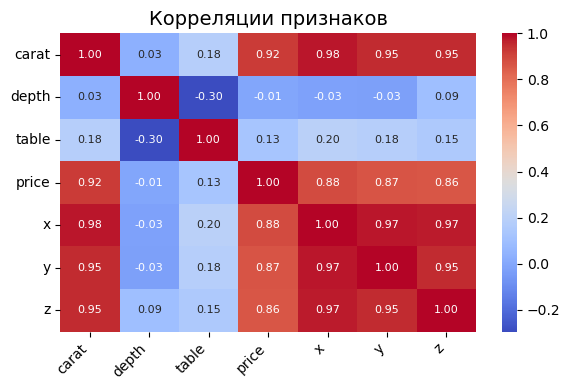

In [11]:
# так нагляднее (сделала для себя)
import seaborn as sns

plt.figure(figsize=(6, 4))  

sns.heatmap(
    data.corr(numeric_only=True),
    annot=True,             
    fmt='.2f',               
    cmap='coolwarm',         
    annot_kws={'size': 8}    
)

plt.title('Корреляции признаков', fontsize=14)
plt.xticks(rotation=45, ha='right')  
plt.yticks(rotation=0)               
plt.tight_layout()
plt.show()

### Задание 4 (1 балл)  

Так как линейная модель складывает значения признаков с некоторыми весами, нам нужно аккуратно обработать категориальные признаки. Закодируйте категориальные переменные при помощи OneHot-кодирования ([`pd.get_dummies`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.get_dummies.html) или `sklearn.OneHotEncoder`). Не забудьте поставить значение параметра `drop_first` равным `True`.

Сколько получилось столбцов в таблице `data`?

In [12]:
# кол-во столбцов до
data.shape[1]

10

In [13]:
data.head(3)

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31


In [14]:
# ваш код здесь
data = pd.get_dummies(data, drop_first=True, dummy_na = False)

In [15]:
data.head(2)

,carat,depth,table,price,x,y,z,cut_Good,cut_Ideal,cut_Premium,...,color_H,color_I,color_J,clarity_IF,clarity_SI1,clarity_SI2,clarity_VS1,clarity_VS2,clarity_VVS1,clarity_VVS2
0,0.23,61.5,55.0,326,3.95,3.98,2.43,False,True,False,...,False,False,False,False,False,True,False,False,False,False
1,0.21,59.8,61.0,326,3.89,3.84,2.31,False,False,True,...,False,False,False,False,True,False,False,False,False,False


In [16]:
# кол-во столбцов после
data.shape[1]

24

### Задание 5 (1 балл)

Создайте матрицу `X`, содержащую все признаки, и не содержащую целевую переменную `price`.  
Также создайте вектор `y`, содержащий целевую переменную `price`.

In [17]:
# ваш код здесь
X = data.drop('price', axis=1)
y = data['price']

In [18]:
y.head(2)

0    326
1    326
Name: price, dtype: int64

In [19]:
X.head(2)

,carat,depth,table,x,y,z,cut_Good,cut_Ideal,cut_Premium,cut_Very Good,...,color_H,color_I,color_J,clarity_IF,clarity_SI1,clarity_SI2,clarity_VS1,clarity_VS2,clarity_VVS1,clarity_VVS2
0,0.23,61.5,55.0,3.95,3.98,2.43,False,True,False,False,...,False,False,False,False,False,True,False,False,False,False
1,0.21,59.8,61.0,3.89,3.84,2.31,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False


In [20]:
X = X.astype('float64')

In [21]:
X.head(2)

,carat,depth,table,x,y,z,cut_Good,cut_Ideal,cut_Premium,cut_Very Good,...,color_H,color_I,color_J,clarity_IF,clarity_SI1,clarity_SI2,clarity_VS1,clarity_VS2,clarity_VVS1,clarity_VVS2
0,0.23,61.5,55.0,3.95,3.98,2.43,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,0.21,59.8,61.0,3.89,3.84,2.31,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


Разделите выборку на тренировочную и тестовую. Долю тестовой выборки укажите равной `0.3`

При разбиении укажите `random_state = 42`

In [22]:
from sklearn.model_selection import train_test_split

# ваш код здесь
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.3, random_state=42)

### Задание 6 (1 балл)

Зачастую при использовании линейных моделей вещественные признаки масштабируются.  В этой задаче масштабируйте вещественные признаки тренировочной и тестовой выборок при помощи модуля `StandardScaler`

*  Обучите (`fit`) scaler на тренировочных данных
*  Преобразуйте (`transform`) и трейн, и тест

После применения масштабирования матрица перестает быть объектом `pandas.DataFrame` - решите эту проблему

In [23]:
from sklearn.preprocessing import StandardScaler

In [24]:
# ваш код здесь
scaler = StandardScaler()

scaler.fit(Xtrain)                          
train_x_scaler = scaler.transform(Xtrain)   
test_x_scaler = scaler.transform(Xtest)    

In [25]:
train_x_scaler = pd.DataFrame(train_x_scaler)
test_x_scaler = pd.DataFrame(test_x_scaler)

In [26]:
type(train_x_scaler)

pandas.core.frame.DataFrame

In [27]:
train_x_scaler.head(2)

,0,1,2,3,4,5,6,7,8,9,...,13,14,15,16,17,18,19,20,21,22
0,0.862659,-0.311437,-0.207099,1.055581,0.986556,0.968253,-0.314881,1.227398,-0.585893,-0.539653,...,2.329335,-0.333294,-0.234494,-0.184885,-0.568277,-0.451216,-0.422668,-0.542475,-0.270252,3.121212
1,-1.029889,0.178549,-0.656213,-1.207734,-1.202544,-1.168276,-0.314881,1.227398,-0.585893,-0.539653,...,-0.429307,-0.333294,-0.234494,-0.184885,-0.568277,-0.451216,-0.422668,1.843403,-0.270252,-0.320388


### Задание 7 (1 балл)

Обучите линейную регрессию на тренировочной выборке. Выведите r2-score на тренировочной и тестовой выборках

In [28]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [29]:
# ваш код здесь
lr = LinearRegression()
lr.fit(train_x_scaler, ytrain)
y_pred_test = lr.predict(test_x_scaler)
y_pred_train = lr.predict(train_x_scaler)

print(f'Качество на тестовой выборке: {r2_score(ytest, y_pred_test)}')
print(f'Качество на тренировочной выборке: {r2_score(ytrain, y_pred_train)}')

Качество на тестовой выборке: 0.9201866914388086
Качество на тренировочной выборке: 0.9195976267987521


### Задание 8 (1 балл)

Выведите на экран веса, которые линейная регрессия присвоила признакам. Назовите вещественные переменные, оценки коэффициентов которых по модулю на порядок превышают оценки прочих вещественных переменных

In [30]:
# ваш код здесь
lr.coef_

array([ 5338.61567061,   -90.17381703,   -60.33227991, -1100.41885004,
          -6.45891672,   -34.25894462,   170.60293265,   414.36951486,
         339.23920411,   310.65425625,   -83.64002086,  -104.56099268,
        -202.86356354,  -362.00229958,  -442.78356742,  -529.44921589,
         975.93364117,  1611.5716809 ,  1042.92121499,  1670.31849636,
        1817.66420828,  1284.80947523,  1461.03419387])

In [31]:
Xtrain.columns

Index(['carat', 'depth', 'table', 'x', 'y', 'z', 'cut_Good', 'cut_Ideal',
       'cut_Premium', 'cut_Very Good', 'color_E', 'color_F', 'color_G',
       'color_H', 'color_I', 'color_J', 'clarity_IF', 'clarity_SI1',
       'clarity_SI2', 'clarity_VS1', 'clarity_VS2', 'clarity_VVS1',
       'clarity_VVS2'],
      dtype='object')

In [32]:
len(lr.coef_) == len(Xtrain.columns)

True

In [33]:
for i in range(len(lr.coef_))[:6]:              # из вещественных признаков здесь только первые 6, поэтому ограничела вывод
    print(Xtrain.columns[i], '-', abs(lr.coef_[i]))

carat - 5338.615670614767
depth - 90.17381703342367
table - 60.332279910273854
x - 1100.418850039302
y - 6.458916720532638
z - 34.258944620882026


Значитальный перевес в значениях коэффициентов у признаков **carat** и **x**.

## Попытка улучшить качество модели

Эта часть является творческой, и задания в ней немного сложнее, чем предыдущие.  
Поэтому за каждое из них можно получить до двух баллов.

### Задание 9 (2 балла)

Как можно заметить из анализа корреляционной матрицы в задании 3, между некоторыми признаками имеется сильная корреляция, что может быть индикатором проблемы *мультиколлинеарности*. Различия в порядке коэффициентов, выявленные в предыдущей задаче, также свидетельствуют об этом. Для решения этой проблемы можно либо исключить некоторые признаки из модели (например, если признак линейно зависим с какими-то другими, его можно исключить из модели, т.е. удалить из матрицы объект-признак и заново обучить модель).

Удалите из матриц `Xtrain` и `Xtest` признак, который наиболее сильно коррелирует с остальными. Заново обучите модель и оцените её качество. Улучшилось ли качество модели?

Попробуйте удалить какой-то другой признак (можете попробовать несколько вариантов). Помогло ли это улучшить качество модели?

In [34]:
data.shape

(53940, 24)

In [35]:
np.linalg.matrix_rank(data.corr(numeric_only=True))

np.int64(24)

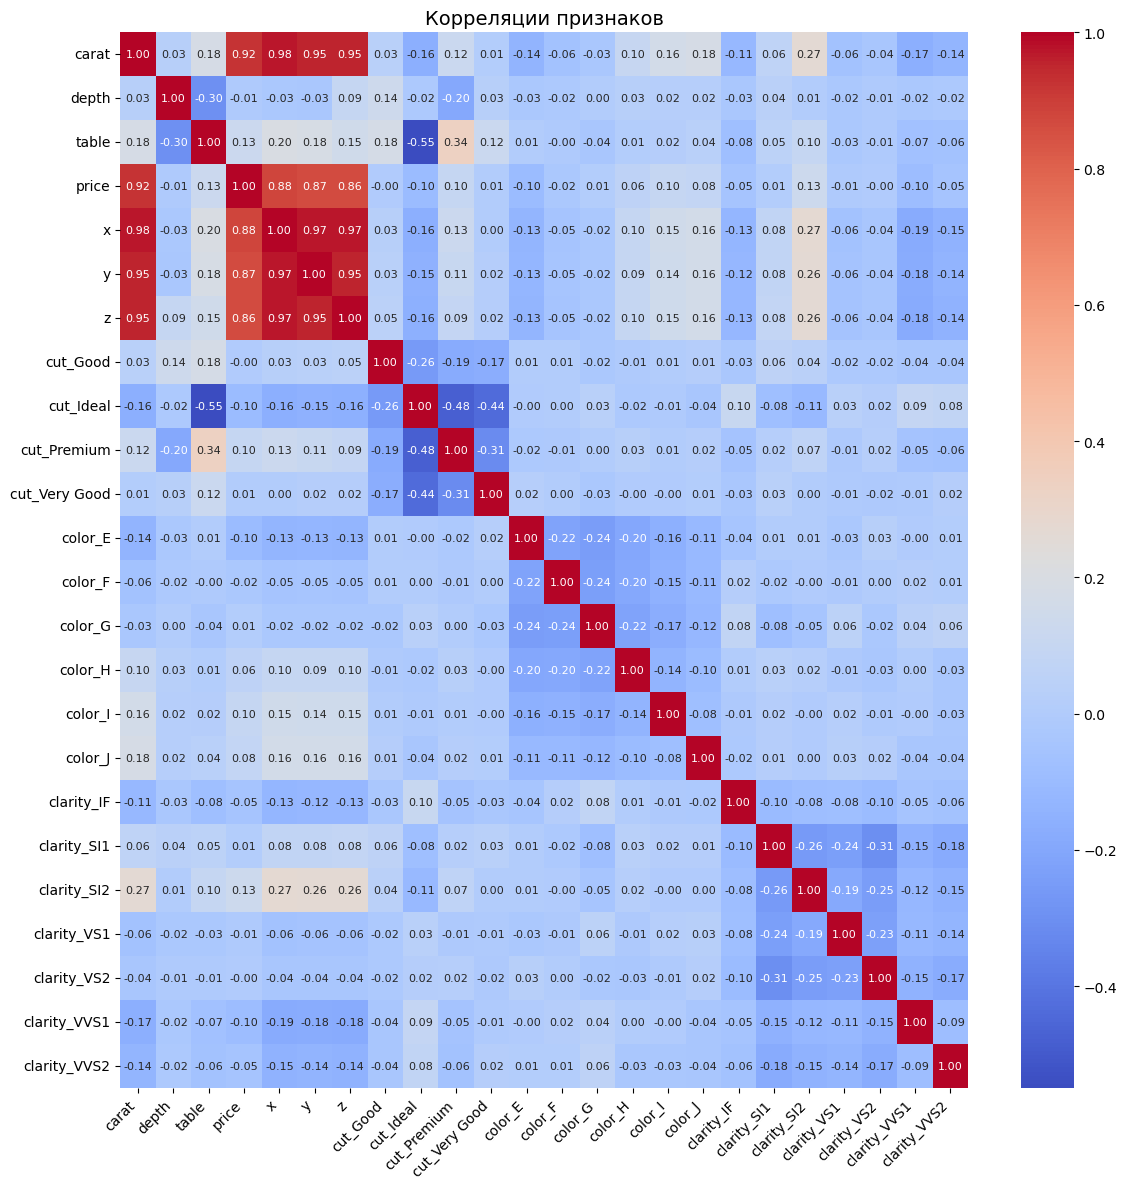

In [36]:
import seaborn as sns

plt.figure(figsize=(12, 12))  

sns.heatmap(
    data.corr(numeric_only=True),
    annot=True,              # показываем значения
    fmt='.2f',               # 2 знака после запятой
    cmap='coolwarm',         # цветовая схема
    annot_kws={'size': 8}    # размер шрифта аннотаций
)

plt.title('Корреляции признаков', fontsize=14)
plt.xticks(rotation=45, ha='right')  
plt.yticks(rotation=0)              
plt.tight_layout()
plt.show();

Больше всего коррелирует с другими признаками **'x'**. Удалим сначала его.

In [37]:
# без 'x'
Xtrain_without_x = Xtrain.drop('x', axis=1)
Xtest_without_x = Xtest.drop('x', axis=1)

In [42]:
scaler_without_x = StandardScaler()

scaler_without_x.fit(Xtrain_without_x)                          
train_x_scaler_without_x = pd.DataFrame(scaler_without_x.transform(Xtrain_without_x))   
test_x_scaler_without_x = pd.DataFrame(scaler_without_x.transform(Xtest_without_x))

In [43]:
lr2 = LinearRegression()
lr2.fit(train_x_scaler_without_x, ytrain)
y_pred_test_2 = lr2.predict(test_x_scaler_without_x)
y_pred_train_2 = lr2.predict(train_x_scaler_without_x)

print(f'Качество на тестовой выборке: {r2_score(ytest, y_pred_test_2)}')
print(f'Качество на тренировочной выборке: {r2_score(ytrain, y_pred_train_2)}')

Качество на тестовой выборке: 0.9189265553479818
Качество на тренировочной выборке: 0.9181118150667532


Качество модели **снизилось**.

**Ответ:** Судя по заданию 3  и наглядному коду выше видна мультиколлинеарность между признаками 'carat' и 'x', 'y', 'z' (больше всего с 'x'). 

Я бы удалила все три признака сразу и оставила только 'carat', но для чистоты эксперимента буду удалять их по одному и смотреть как будет менятться результат прогноза))

Сначала удалю 'y', 'z', так как у них самые маленькие коэффициенты весов, а затем попробую удалить 'x'

In [44]:
# без 'y'
Xtrain_without_y = Xtrain.drop('y', axis=1)
Xtest_without_y = Xtest.drop('y', axis=1)

In [45]:
scaler_without_y = StandardScaler()

scaler_without_y.fit(Xtrain_without_y)                          
train_x_scaler_without_y = pd.DataFrame(scaler_without_y.transform(Xtrain_without_y))   
test_x_scaler_without_y = pd.DataFrame(scaler_without_y.transform(Xtest_without_y))

In [46]:
lr3 = LinearRegression()
lr3.fit(train_x_scaler_without_y, ytrain)
y_pred_test_3 = lr3.predict(test_x_scaler_without_y)
y_pred_train_3 = lr3.predict(train_x_scaler_without_y)

print(f'Качество на тестовой выборке: {r2_score(ytest, y_pred_test_3)}')
print(f'Качество на тренировочной выборке: {r2_score(ytrain, y_pred_train_3)}')

Качество на тестовой выборке: 0.9201889043414831
Качество на тренировочной выборке: 0.9195974859825768


In [47]:
# без 'y', 'z'
Xtrain_without_yz = Xtrain.drop(columns=['y', 'z'], axis=1)
Xtest_without_yz = Xtest.drop(columns=['y', 'z'], axis=1)

In [49]:
scaler_without_yz = StandardScaler()

scaler_without_yz.fit(Xtrain_without_yz)                          
train_x_scaler_without_yz = pd.DataFrame(scaler_without_yz.transform(Xtrain_without_yz))   
test_x_scaler_without_yz = pd.DataFrame(scaler_without_yz.transform(Xtest_without_yz))

In [50]:
lr4 = LinearRegression()
lr4.fit(train_x_scaler_without_yz, ytrain)
y_pred_test_4 = lr4.predict(test_x_scaler_without_yz)
y_pred_train_4 = lr4.predict(train_x_scaler_without_yz)

print(f'Качество на тестовой выборке: {r2_score(ytest, y_pred_test_4)}')
print(f'Качество на тренировочной выборке: {r2_score(ytrain, y_pred_train_4)}')

Качество на тестовой выборке: 0.920189104854317
Качество на тренировочной выборке: 0.9195930916084882


In [51]:
# без 'x', 'y', 'z'
Xtrain_without_xyz = Xtrain.drop(columns=['x', 'y', 'z'], axis=1)
Xtest_without_xyz = Xtest.drop(columns=['x', 'y', 'z'], axis=1)

In [52]:
scaler_without_xyz = StandardScaler()

scaler_without_xyz.fit(Xtrain_without_xyz)                          
train_x_scaler_without_xyz = pd.DataFrame(scaler_without_xyz.transform(Xtrain_without_xyz))   
test_x_scaler_without_xyz = pd.DataFrame(scaler_without_xyz.transform(Xtest_without_xyz))

In [53]:
lr5 = LinearRegression()
lr5.fit(train_x_scaler_without_xyz, ytrain)
y_pred_test_5 = lr5.predict(test_x_scaler_without_xyz)
y_pred_train_5 = lr5.predict(train_x_scaler_without_xyz)

print(f'Качество на тестовой выборке: {r2_score(ytest, y_pred_test_5)}')
print(f'Качество на тренировочной выборке: {r2_score(ytrain, y_pred_train_5)}')

Качество на тестовой выборке: 0.916194716704243
Качество на тренировочной выборке: 0.9159704730530022


**Вывод:** без 'y' и 'z' модель не теряла качество, а после удаления 'x' стала немного хуже, поэтому я бы оставила все исходные признаки без удалений на исходном Xtrain и Xtest и первую модель обучения 'lr'

### Задание 10 (2 балла)

Иногда генерация новых признаков помогает модели лучше находить взаимосвязи между целевой переменной и признаками. Попробуйте придумать новые признаки и добавить их в модель.  

Помогло ли это улучшить качество модели?

добавила признак **объем** на основании 'x' 'y' 'z' 

In [54]:
Xtrain['volume'] = Xtrain['x'] * Xtrain['y'] * Xtrain['z']
Xtest['volume'] = Xtest['x'] * Xtest['y'] * Xtest['z']

In [55]:
scaler = StandardScaler()

scaler.fit(Xtrain)                          
train_x_scaler = pd.DataFrame(scaler.transform(Xtrain))   
test_x_scaler = pd.DataFrame(scaler.transform(Xtest))

In [56]:
lr6 = LinearRegression()
lr6.fit(train_x_scaler, ytrain)
y_pred_test_6 = lr6.predict(test_x_scaler)
y_pred_train_6 = lr6.predict(train_x_scaler)

print(f'Качество на тестовой выборке: {r2_score(ytest, y_pred_test_6)}')
print(f'Качество на тренировочной выборке: {r2_score(ytrain, y_pred_train_6)}')

Качество на тестовой выборке: 0.9200380139183006
Качество на тренировочной выборке: 0.920097472926017


Ответ: **Качество улучшилось**.

добавила признак **площадь поверхности** на основании 'x' 'y' 

In [57]:
Xtrain['area'] = Xtrain['x'] * Xtrain['y']
Xtest['area'] = Xtest['x'] * Xtest['y']

In [58]:
scaler = StandardScaler()

scaler.fit(Xtrain)                          
train_x_scaler = pd.DataFrame(scaler.transform(Xtrain))   
test_x_scaler = pd.DataFrame(scaler.transform(Xtest))

In [59]:
lr7 = LinearRegression()
lr7.fit(train_x_scaler, ytrain)
y_pred_test_7 = lr7.predict(test_x_scaler)
y_pred_train_7 = lr7.predict(train_x_scaler)

print(f'Качество на тестовой выборке: {r2_score(ytest, y_pred_test_7)}')
print(f'Качество на тренировочной выборке: {r2_score(ytrain, y_pred_train_7)}')

Качество на тестовой выборке: 0.9211575816017967
Качество на тренировочной выборке: 0.9225499300395787


Ответ: **Качество улучшилось**.

добавила признак **Отклонение от идеального стола (53-57%)** на основании 'table'

In [60]:
Xtrain['table_deviation'] = abs(Xtrain['table'] - 55)
Xtest['table_deviation'] = abs(Xtest['table'] - 55)

In [61]:
scaler = StandardScaler()

scaler.fit(Xtrain)                          
train_x_scaler = pd.DataFrame(scaler.transform(Xtrain))   
test_x_scaler = pd.DataFrame(scaler.transform(Xtest))

In [62]:
lr8 = LinearRegression()
lr8.fit(train_x_scaler, ytrain)
y_pred_test_8 = lr8.predict(test_x_scaler)
y_pred_train_8 = lr8.predict(train_x_scaler)

print(f'Качество на тестовой выборке: {r2_score(ytest, y_pred_test_8)}')
print(f'Качество на тренировочной выборке: {r2_score(ytrain, y_pred_train_8)}')

Качество на тестовой выборке: 0.9211527266268638
Качество на тренировочной выборке: 0.9225530446045833


Ответ: **Качество не изменилось**.

добавила признак **Соотношение table/depth** на основании 'table' и 'depth'

In [63]:
Xtrain['table_depth_ratio'] = Xtrain['table'] / Xtrain['depth']
Xtest['table_depth_ratio'] = Xtest['table'] / Xtest['depth']

In [64]:
scaler = StandardScaler()

scaler.fit(Xtrain)                          
train_x_scaler = pd.DataFrame(scaler.transform(Xtrain))   
test_x_scaler = pd.DataFrame(scaler.transform(Xtest))

In [65]:
lr9 = LinearRegression()
lr9.fit(train_x_scaler, ytrain)
y_pred_test_9 = lr9.predict(test_x_scaler)
y_pred_train_9 = lr9.predict(train_x_scaler)

print(f'Качество на тестовой выборке: {r2_score(ytest, y_pred_test_9)}')
print(f'Качество на тренировочной выборке: {r2_score(ytrain, y_pred_train_9)}')

Качество на тестовой выборке: 0.9211450893468391
Качество на тренировочной выборке: 0.9226210482860645


Ответ: **Качество снизилось на test** и **улучшилось на train**

добавила признак **плотность (соотношение объема к карату)** на основании 'volume' и 'carat'

In [67]:
Xtrain['density'] = Xtrain['volume'] / Xtrain['carat'] 
Xtest['density'] = Xtest['volume'] / Xtest['carat'] 

In [68]:
scaler = StandardScaler()

scaler.fit(Xtrain)                          
train_x_scaler = pd.DataFrame(scaler.transform(Xtrain))   
test_x_scaler = pd.DataFrame(scaler.transform(Xtest))

In [73]:
lr10 = LinearRegression()
lr10.fit(train_x_scaler, ytrain)
y_pred_test_10 = lr10.predict(test_x_scaler)
y_pred_train_10 = lr10.predict(train_x_scaler)

print(f'Качество на тестовой выборке: {r2_score(ytest, y_pred_test_10)}')
print(f'Качество на тренировочной выборке: {r2_score(ytrain, y_pred_train_10)}')

Качество на тестовой выборке: 0.9096089137229612
Качество на тренировочной выборке: 0.9230899502973989


Ответ: **На тренировочной качество растет**, а **на тестовой - падает**.

## Выводы

Сделайте выводы, исходя из проделанной работы.

Какого наилучшего качества удалось добиться? Хорошее ли это качество на ваш взгляд? Что для этого вам пришлось сделать?

**Выводы:**

При удалении признаков 'x', 'y', 'z' из исходного датасета качество падало. Также при добавлении новых признаков (кроме объем и площадь поверхности) прослеживалось падение качества на тестовой выборке и роста качества на тренировочной, что говорило о том, что модель стала переобучаться.

Самого лучшего качества получилось добиться на модели 7:

- R2 на тестовой выборке: 0.9211575816017967
- R2 на тренировочной выборке: 0.9225499300395787

В которой оставили все исходные признаки без изменения и добавили два признака: объем и площадь поверхности.

На мой взгляд качество равное 0.92 - это очень хорошее качество.

Правда, мы не проверяли датасет на выбросы, и, соответственно, если бы они были, то мы никак с ними не проработали, но тем не менее добились очень хорошего качества обучения.